In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("MIT-805-Group-Assignment")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "6g")
    .getOrCreate()
)
sc = spark.sparkContext
spark

In [3]:
file_path = '/content/drive/My Drive/Working_data/yellow_tripdata_*.parquet'

In [4]:
df = spark.read.parquet(file_path) # loading all data 13GB
df.show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|       2| 2011-01-01 00:10:00|  2011-01-01 00:12:00|              4|          0.0|         1|              NULL|         145|         145|           1|        2.9|  0.5|    0.5|      0.2

In [5]:
from pyspark.sql.functions import col, unix_timestamp, year, month, hour, when, date_format
import glob

def load_taxi_data(path):
    return spark.read.parquet(path)

def transform_taxi_data(df):
    return (df
        .select(
            col("VendorID"),
            col("tpep_pickup_datetime"),
            col("tpep_dropoff_datetime"),
            col("passenger_count"),
            col("trip_distance"),
            col("fare_amount"),
            col("payment_type"),
            col("tip_amount"),
            col("RatecodeID"),
            col("total_amount")
        )
        .withColumn(
            "trip_duration_minutes",
            (unix_timestamp(col("tpep_dropoff_datetime")) - unix_timestamp(col("tpep_pickup_datetime"))) / 60
        )
        .withColumn("day_of_week", date_format(col("tpep_pickup_datetime"), "EEEE"))
        .withColumn("year", year(col("tpep_pickup_datetime")))
        .withColumn("month", date_format(col("tpep_pickup_datetime"), "MMM"))
        .withColumn(
            "time_of_day",
            when(hour(col("tpep_pickup_datetime")).between(5, 11), "Morning")
            .when(hour(col("tpep_pickup_datetime")).between(12, 17), "Day")
            .otherwise("Night")
        )
        .withColumn(
            "payment_type_desc",
            when(col("payment_type") == 1, "Credit Card")
            .when(col("payment_type") == 2, "Cash")
            .when(col("payment_type") == 3, "No Charge")
            .when(col("payment_type") == 4, "Dispute")
            .when(col("payment_type") == 5, "Unknown")
            .otherwise("Other")
        )
        .withColumn(
            "rate_code_desc",
            when(col("RatecodeID") == 1, "Standard Rate")
            .when(col("RatecodeID") == 2, "JFK")
            .when(col("RatecodeID") == 3, "Newark")
            .when(col("RatecodeID") == 4, "Nassau or Westchester")
            .when(col("RatecodeID") == 5, "Negotiated Fare")
            .when(col("RatecodeID") == 6, "Group Ride")
            .otherwise("Other")
        )
        .drop("tpep_dropoff_datetime", "RatecodeID", "payment_type")
    )

def clean_and_cache_taxi_data(df):
    df_clean = df.filter(
        (col("trip_distance") > 0) &
        (col("fare_amount") > 0) &
        (col("passenger_count") > 0)
    ).cache()
    df_clean.count()  # trigger cache
    return df_clean

def process_monthly_file(path):
    df = load_taxi_data(path)
    df = transform_taxi_data(df)
    df = clean_and_cache_taxi_data(df)
    return df

# ----------------------------
# Process 2016 and 2017 Files
# ----------------------------

# Get all parquet files for 2016 and 2017 which is 3.2 GB
files_2016 = glob.glob("/content/drive/My Drive/Working_data/yellow_tripdata_2016-*.parquet")
files_2017 = glob.glob("/content/drive/My Drive/Working_data/yellow_tripdata_2017-*.parquet")

# Process and union 2016
df_2016 = None
for f in sorted(files_2016):
    print(f"Processing {f}...")
    df_month = process_monthly_file(f)
    df_2016 = df_month if df_2016 is None else df_2016.unionByName(df_month)

# Process and union 2017
df_2017 = None
for f in sorted(files_2017):
    print(f"Processing {f}...")
    df_month = process_monthly_file(f)
    df_2017 = df_month if df_2017 is None else df_2017.unionByName(df_month)

# Combine both years
df_all = df_2016.unionByName(df_2017)

# ----------------------------
# Inspect Final Dataset
# ----------------------------
df_all.printSchema()
print("Final record count:", df_all.count())

Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-01.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-02.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-03.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-04.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-05.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-06.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-07.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-08.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-09.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-10.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-11.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-12.parquet...
Proc

# Anomaly Detection

In [6]:
# Summary
from pyspark.sql.functions import count

df_all.groupBy().agg(
    count(when(col("trip_distance") > 50, True)).alias("long_trip_outliers"), # Trip distance outliers
    count(when(col("fare_amount") > 200, True)).alias("high_fare_outliers"),     # Fare anomalies
    count(when(col("passenger_count") > 6, True)).alias("passenger_outliers") # Passenger count anomalies
).show()

+------------------+------------------+------------------+
|long_trip_outliers|high_fare_outliers|passenger_outliers|
+------------------+------------------+------------------+
|             10079|             12275|               808|
+------------------+------------------+------------------+



# EDA

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

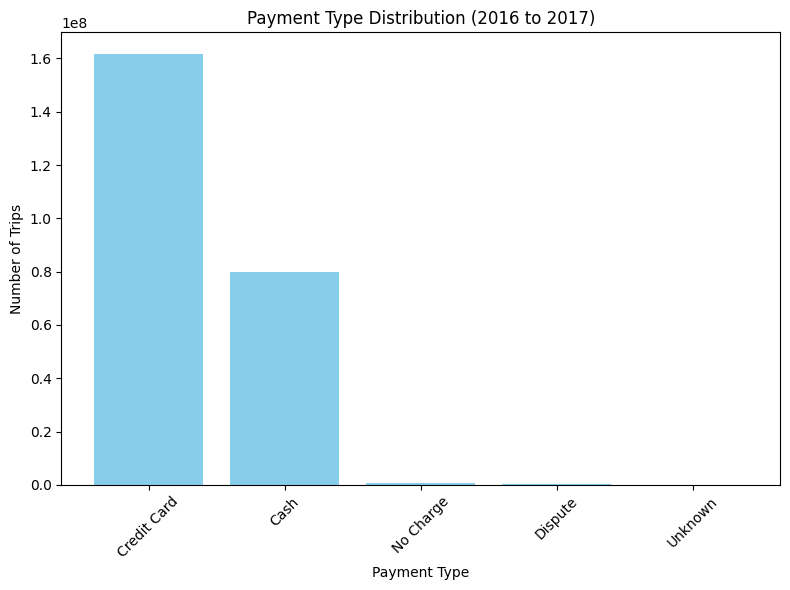

In [8]:

payment_summary = df_all.groupBy("payment_type_desc").count().orderBy("count", ascending=False).toPandas()

# Plot as bar chart
plt.figure(figsize=(8,6))
plt.bar(payment_summary['payment_type_desc'], payment_summary['count'], color="skyblue")
plt.title("Payment Type Distribution (2016 to 2017)")
plt.xlabel("Payment Type")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("/content/drive/My Drive/Working_data/payment_type_distribution_2016.png")
# Show plot
plt.show()

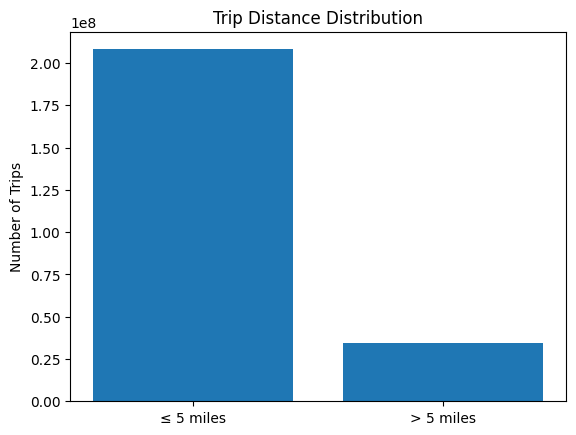

In [9]:
trip_distance_summary = df_all.groupBy(
    (col("trip_distance") <= 5).alias("short_trip")
).count().toPandas()

trip_distance_summary['short_trip'] = trip_distance_summary['short_trip'].map({True: "≤ 5 miles", False: "> 5 miles"})

plt.bar(trip_distance_summary['short_trip'], trip_distance_summary['count'])
plt.title("Trip Distance Distribution")
plt.ylabel("Number of Trips")

# Save to PNG
plt.savefig("/content/drive/My Drive/Working_data/Trip_Distance_Distribution.png")
plt.show()

### Weekly demand

In [10]:
# Aggregate by day_of_week and time_of_day
weekly_demand = df_all.groupBy("day_of_week", "time_of_day") \
    .count() \
    .orderBy("day_of_week", "time_of_day") \
    .toPandas()

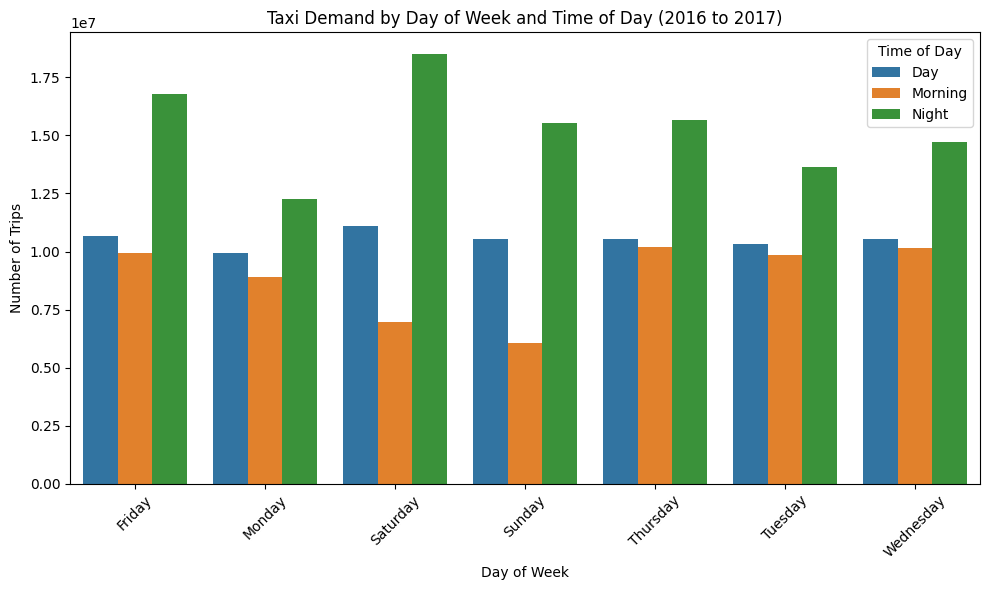

In [11]:
plt.figure(figsize=(10,6))
sns.barplot(data=weekly_demand, x="day_of_week", y="count", hue="time_of_day")

plt.title("Taxi Demand by Day of Week and Time of Day (2016 to 2017)")
plt.xlabel("Day of Week")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.legend(title="Time of Day")
plt.tight_layout()

# Save plot
plt.savefig("/content/drive/My Drive/Working_data/weekly_demand_2016.png", dpi=300)

# Show plot
plt.show()

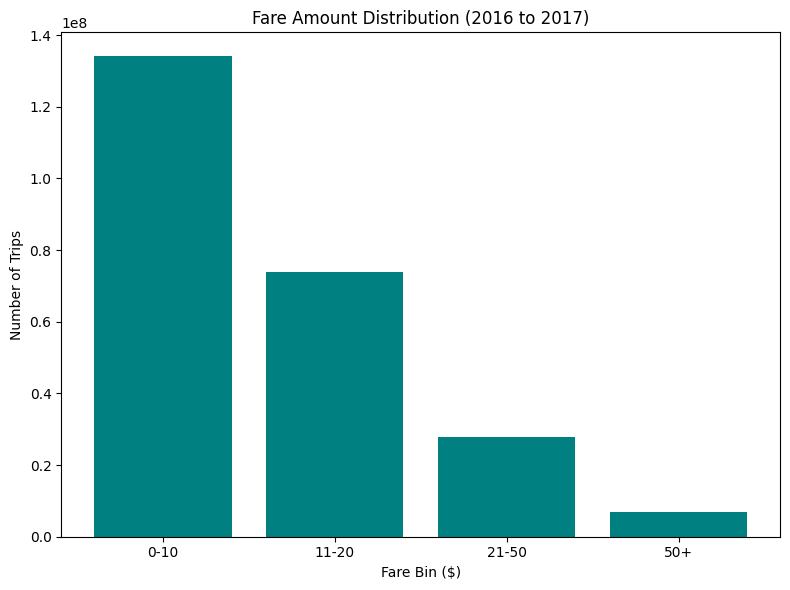

In [12]:
# Convert to Pandas
fare_bins_pd = df_all.select(
    when(col("fare_amount") <= 10, "0-10")
    .when(col("fare_amount") <= 20, "11-20")
    .when(col("fare_amount") <= 50, "21-50")
    .otherwise("50+").alias("fare_bin")
).groupBy("fare_bin").count().toPandas()

# Plot as bar chart
plt.figure(figsize=(8,6))
plt.bar(fare_bins_pd['fare_bin'], fare_bins_pd['count'], color="teal")
plt.title("Fare Amount Distribution (2016 to 2017)")
plt.xlabel("Fare Bin ($)")
plt.ylabel("Number of Trips")
plt.tight_layout()

# Save plot
plt.savefig("/content/drive/My Drive/Working_data/Fare Amount Distribution.png", dpi=300)

# Show plot
plt.show()



In [13]:
monthly_distribution = df_all.groupBy("month").count().orderBy("month")
monthly_distribution.show()

+-----+--------+
|month|   count|
+-----+--------+
|  Apr|21823002|
|  Aug|18236169|
|  Dec|19762363|
|  Feb|20414323|
|  Jan|20483858|
|  Jul|18750131|
|  Jun|20646529|
|  Mar|22355263|
|  May|21788382|
|  Nov|19204871|
|  Oct|20446059|
|  Sep|18913738|
+-----+--------+



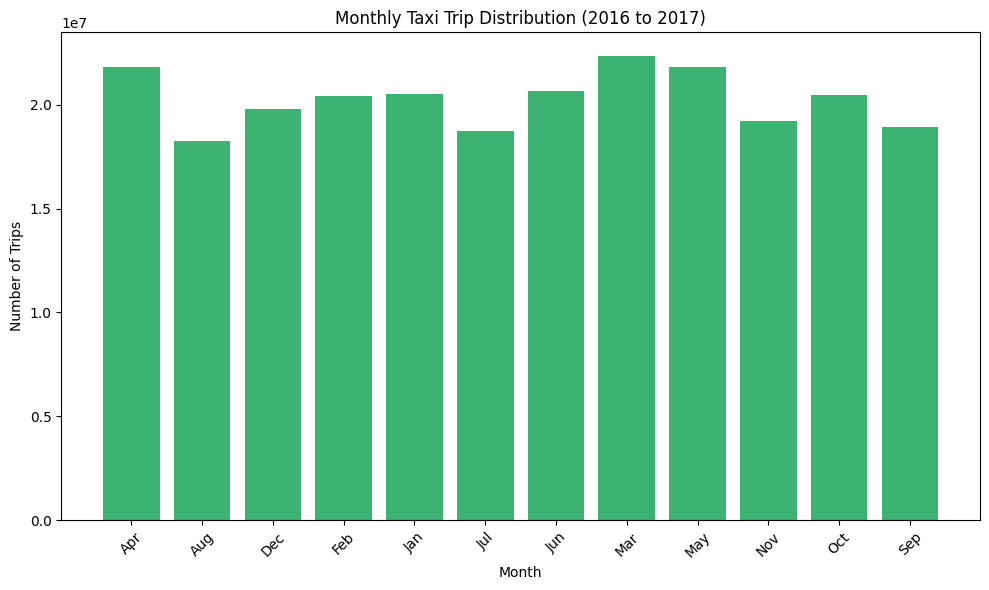

In [14]:
# Convert to Pandas
monthly_pd = monthly_distribution.toPandas()

# Plot as bar chart
plt.figure(figsize=(10,6))
plt.bar(monthly_pd['month'], monthly_pd['count'], color="mediumseagreen")
plt.title("Monthly Taxi Trip Distribution (2016 to 2017)")
plt.xlabel("Month")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()

# Save plot
plt.savefig("/content/drive/My Drive/Working_data/monthly_trip_distribution_2016.png", dpi=300)
# Show plot
plt.show()